### Building a Basic Chatbot - with LangGraph (GRAPH API)

In [8]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

from langgraph.graph.message import add_messages # these are called a reducers which used to append(add) future messages on it.

In [9]:
class State(TypedDict):
    # Messages have the type "list". The  `add_messages` function 
    # In the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

In [10]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
load_dotenv()

api_key = os.getenv("GROQ_API_KEY")

if not api_key:
    raise ValueError("GROQ_API_KEY is missing from .env")

In [11]:
import atexit
import ssl
import tempfile
from pathlib import Path

import httpx

# Use Windows' trusted CA store because this environment's certifi bundle fails to parse.
windows_ca_pems = [
    ssl.DER_cert_to_PEM_cert(cert)
    for cert, encoding, trust in ssl.enum_certificates("ROOT")
    if encoding == "x509_asn"
    and (trust is True or "1.3.6.1.5.5.7.3.1" in trust)
]
if not windows_ca_pems:
    raise RuntimeError("No trusted server certificates found in the Windows ROOT store.")

windows_ca_bundle = "".join(windows_ca_pems)
ssl_context = ssl.create_default_context(cadata=windows_ca_bundle)

_ca_bundle_file = tempfile.NamedTemporaryFile(
    mode="w", suffix=".pem", encoding="ascii", delete=False
)
try:
    _ca_bundle_file.write(windows_ca_bundle)
finally:
    _ca_bundle_file.close()

os.environ["REQUESTS_CA_BUNDLE"] = _ca_bundle_file.name
atexit.register(lambda: Path(_ca_bundle_file.name).unlink(missing_ok=True))

http_client = httpx.Client(verify=ssl_context, timeout=30)
http_async_client = httpx.AsyncClient(verify=ssl_context, timeout=30)

In [12]:
print("SSL configured with", len(windows_ca_pems), "Windows trusted CA certificates")

SSL configured with 27 Windows trusted CA certificates


In [9]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    http_client=http_client,
    http_async_client=http_async_client,
)

print(llm.invoke("Hello"))

content='Hello! How can I assist you today?' additional_kwargs={'reasoning_content': 'The user says "Hello". We need to respond appropriately. No special instructions. Just greet back.'} response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 72, 'total_tokens': 111, 'completion_time': 0.080600749, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.003810571, 'prompt_tokens_details': None, 'queue_time': 0.210855612, 'total_time': 0.08441132}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a7bb72c24', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a13065-296b-7fb3-bb25-c2c5ae69c88e-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 72, 'output_tokens': 39, 'total_tokens': 111, 'output_token_details': {'reasoning': 21}}


In [13]:
llm = init_chat_model(
    "groq:openai/gpt-oss-120b",
    http_client=http_client,
    http_async_client=http_async_client,
)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001799D6902F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001799D6906E0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'), http_client=<httpx.Client object at 0x000001799D27C6E0>, http_async_client=<httpx.AsyncClient object at 0x000001799D27EBA0>)

In [14]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [15]:
graph_builder = StateGraph(State)

# Adding node
graph_builder.add_node("llmchatbot", chatbot)

# Adding Edge
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## compile the graph
graph=graph_builder.compile()

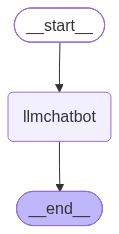

In [16]:
## Visualization the graph

from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass 

In [17]:
response = graph.invoke({"messages": "Hi"})

In [ ]:
print (response["messages"])
print (response["messages"][-1].content)


[HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='50726a8a-9bfe-47ba-9959-7f08a80b152a'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi". Should greet and ask how can help. Follow policies.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 72, 'total_tokens': 113, 'completion_time': 0.086199797, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.003732611, 'prompt_tokens_details': None, 'queue_time': 0.213033918, 'total_time': 0.089932408}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_86dc843b12', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ff3-317c-7943-9f3f-35f5705d95f6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 41, 'total_tokens': 113, 'output_token_details': {'reasoning': 23}})]


In [18]:
## Insted of using .invoke i am using stream here.
for event in graph.stream({"messages": "Hi, How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing great, thanks for asking. How can I assist you today?


### Chatboat With Tool

In [19]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results = 2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [21]:
## Custom function to use the tool in the graph
def multiple(a: int, b: int) -> int:
    """
    Multiple a and b

    Args:
        a (int): The first number.
        b (int): The second number.

    Returns:
        int: The product of a and b.
    """
    return a*b

In [22]:
tools = [tool, multiple]
llm_with_tools = llm.bind_tools(tools);
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001799D6902F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001799D6906E0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'), http_client=<httpx.Client object at 0x000001799D27C6E0>, http_async_client=<httpx.AsyncClient object at 0x000001799D27EBA0>), kwargs={'tools': [{'type'

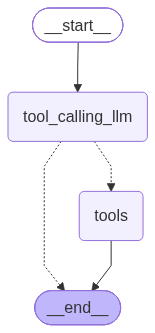

In [23]:
## StateGraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

## Node Defination
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Adding Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", END)

## Compile the graph

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [24]:
response = graph.invoke({"messages": "What's the recent ai news"});
response["messages"][-1].content

'{"query": "latest AI news week", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.fiercehealthcare.com/health-tech/weekly-rundown-hhs-awards-15m-ai-projects-arcadia-launches-portfolio-solutions", "title": "Weekly Rundown: Nextech taps Assort Health, EliseAI for agentic AI; Elsevier rolls out clinical AI tool for nurses | Fierce Healthcare", "content": "Stay up to date on the latest in health tech, digital health and health AI news with this weekly brief. Read below for news from the week of Oct. 5 to 9.\\n\\n### Nextech teams up with Assort Health, EliseAI for agentic AI tools\\n\\nNextech is partnering with Assort Health and EliseAI to integrate agentic AI tools into its specialty electronic health record (EHR) platform. Through the partnerships, Nextech clients now have a choice of two AI patient access platforms integrated into the company\'s specialty healthcare operating system, the companies said. [...] Awards\\n  + DEI Awards\\n  + Inn

In [27]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What's the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_dedefada-7661-40ce-a4c4-2e31508093d8)
 Call ID: fc_dedefada-7661-40ce-a4c4-2e31508093d8
  Args:
    query: latest AI news October 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://hellogrowth.ai/en/blog/google-ai-news-october-2026", "title": "Google AI news October 2026 · Hello Growth", "content": "Google had a busy first half of October. Most of the news was about agents: AI that does not just answer, but carries out tasks itself. Below, for each development: what happened, who it matters to and where to read more. Checked on 11 October 20

In [31]:
response = graph.invoke({"messages": "What's 2 multiply by 3"});
response

{'messages': [HumanMessage(content="What's 2 multiply by 3", additional_kwargs={}, response_metadata={}, id='f109b98c-cc59-486f-8b46-0dabe7a69418'),
  AIMessage(content='2\u202f×\u202f3\u202f=\u202f6.', additional_kwargs={'reasoning_content': 'User asks "What\'s 2 multiply by 3". Simple arithmetic: 2 * 3 = 6. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 351, 'total_tokens': 397, 'completion_time': 0.095894134, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.016363108, 'prompt_tokens_details': None, 'queue_time': 0.414872687, 'total_time': 0.112257242}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a7bb72c24', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a130a5-e03c-7dc3-bf01-b4f24bbbb104-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 351, 'output_tokens': 46, 'total_tokens': 397, 'output_token_details

In [32]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What's 2 multiply by 3
================================== Ai Message ==================================

2 × 3 = 6.


In [33]:
response = graph.invoke({"messages": "What's 5 multiply by 4 and then multiply by 10"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What's 5 multiply by 4 and then multiply by 10
================================== Ai Message ==================================

5 × 4 = 20, and 20 × 10 = 200. So the result is **200**.


In [34]:
response = graph.invoke({"messages": "Give me recent ai news and then multiply by 5 by 10"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and then multiply by 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_55db8c79-bfa1-4f00-8342-1147ef658139)
 Call ID: fc_55db8c79-bfa1-4f00-8342-1147ef658139
  Args:
    query: AI news October 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.facebook.com/NikeeluGundaofficial/posts/5-big-ai-updates-you-should-know-today-october-7-2026ai-is-moving-beyond-chatbot/1773372201461569", "title": "Nikeelu Gunda", "content": "Log in\n\nLog in\n\nForgotten account?\n\n## Nikeelu Gunda's post\n\n  \n\n[](\n\n### Nikeelu Gunda\n\n4 days ago\n\n4d · Verappa · Sai Abhyankkar, Arivu, Arun Srinivasan

### ReACT Agent Architecture

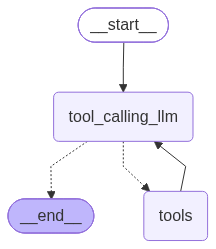

In [25]:
## StateGraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

## Node Defination
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Adding Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")
builder.add_edge("tool_calling_llm", END)

## Compile the graph

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [36]:
response = graph.invoke({"messages": "Give me recent ai news and then multiply by 5 by 10"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and then multiply by 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_336acff5-487c-47c1-90ce-f30a782c7b95)
 Call ID: fc_336acff5-487c-47c1-90ce-f30a782c7b95
  Args:
    query: latest AI news October 2026
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.facebook.com/jonathanjmast/posts/%F0%9D%97%94%F0%9D%97%9C-%F0%9D%97%A1%F0%9D%97%98%F0%9D%97%AA%F0%9D%97%A6-%F0%9D%97%A7%F0%9D%97%9B%F0%9D%97%94%F0%9D%97%A7-%F0%9D%97%A0%F0%9D%97%94%F0%9D%97%A7%F0%9D%97%A7%F0%9D%97%98%F0%9D%97%A5%F0%9D%97%A6-%F0%9D%97%A7%F0%9D%97%A2-%F0%9D%97%98%F0%9D%97%A1%F0%9D%97%A7%F0%9D%97%A5%F0%9

### Adding Memory In Agentic Graph

In [26]:
response = graph.invoke({"messages": "My Name is Karan"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

My Name is Karan
================================== Ai Message ==================================

Nice to meet you, Karan! How can I assist you today?


In [27]:
response = graph.invoke({"messages": "What is my name"});
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don’t actually know your name—unless you’d like to share it with me, I can’t guess it. If you tell me what you’d like to be called, I’ll be happy to use that name in our conversation!


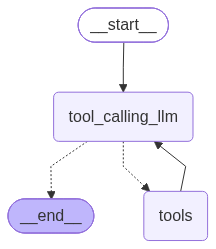

In [28]:
## StateGraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver();

## Node Defination
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Adding Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")
builder.add_edge("tool_calling_llm", END)

## Compile the graph

graph = builder.compile(checkpointer=memory)

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
config = {"configurable" : {"thread_id": "1"}}

response = graph.invoke({"messages" : "Hi my name is Karan" }, config=config)

response

{'messages': [HumanMessage(content='Hi my name is Karan', additional_kwargs={}, response_metadata={}, id='3f89c62a-870c-4615-b327-2dcedbaf5909'),
  AIMessage(content='Nice to meet you, Karan! How can I help you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi my name is Karan". Likely they want a greeting. Should respond friendly. No need to use tools.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 350, 'total_tokens': 404, 'completion_time': 0.111573092, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.015585186, 'prompt_tokens_details': None, 'queue_time': 0.374151702, 'total_time': 0.127158278}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_bb691ea66b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13496-20b1-7bf2-9c88-bc5df973d5c0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 350, 'output_tok

In [ ]:
response = graph.invoke({"messages" : "WHat my name"}, config=config)

response

{'messages': [HumanMessage(content='Hi my name is Karan', additional_kwargs={}, response_metadata={}, id='3f89c62a-870c-4615-b327-2dcedbaf5909'),
  AIMessage(content='Nice to meet you, Karan! How can I help you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi my name is Karan". Likely they want a greeting. Should respond friendly. No need to use tools.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 350, 'total_tokens': 404, 'completion_time': 0.111573092, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.015585186, 'prompt_tokens_details': None, 'queue_time': 0.374151702, 'total_time': 0.127158278}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_bb691ea66b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13496-20b1-7bf2-9c88-bc5df973d5c0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 350, 'output_tok

### Streaming

Methods: stream() and astream()
- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state
- values: This streams the full state of the graph after each node is called.
- updates: This streams updates to the state of the graph after each node is called.

In [34]:
from langgraph.checkpoint.memory import MemorySaver
# from langgraph.graph import START, END, StateGraph
memory = MemorySaver()

In [35]:
def superbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

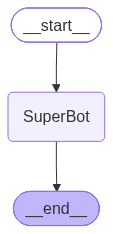

In [39]:
graph = StateGraph(State)

## Node
graph.add_node("SuperBot", superbot)

## Edges
graph.add_edge(START, "SuperBot")
graph.add_edge("SuperBot", END)

graph_builder = graph.compile(checkpointer=memory)

## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [44]:
config = {"configurable" : {"thread_id": "1"}}

response = graph_builder.invoke({"messages" : "Hi my name is Karan and i like Money, mind and peace" }, config=config)

for m in response["messages"]:
    m.pretty_print()
    

================================ Human Message =================================

Hi my name is Karan and i like Money, mind and peace
================================== Ai Message ==================================

Hey Karan! Nice to meet you. It sounds like you’ve got a great mix of interests—money, the mind, and peace. Those can lead to some fascinating conversations. 

- **Money**: Are you into investing, entrepreneurship, or just curious about personal finance?
- **Mind**: Do you enjoy reading about psychology, philosophy, or maybe practicing meditation?
- **Peace**: Is that more about inner calm, global harmony, or something else?

I’d love to hear more about what draws you to each of these areas!
================================ Human Message =================================

Hi my name is Karan and i like Money, mind and peace
================================== Ai Message ==================================

Welcome back, Karan! It’s great to hear you’re drawn to **money**, **

In [ ]:
### It will display only the last message or updated message as response : stream_mode = "updates"
config = {"configurable" : {"thread_id": "3"}}

for m in graph_builder.stream({"messages" : "Hi my name is Karan and i like Money, mind and peace" }, config=config, stream_mode="updates"):
    print (m)

{'SuperBot': {'messages': [AIMessage(content='Nice to meet you, Karan! It’s great that you’ve identified three powerful pillars that interest you:\n\n1. **Money** – Building financial security, investing, and creating wealth.\n2. **Mind** – Exploring thoughts, learning, personal growth, and mental well‑being.\n3. **Peace** – Finding calm, balance, and a sense of inner harmony.\n\nIf you’d like, we can dive deeper into any of these areas—whether it’s tips on budgeting or investing, strategies for sharpening your mind, practices for cultivating peace, or even how the three can complement each other. Just let me know where you’d like to start!', additional_kwargs={'reasoning_content': 'The user repeats same statement. Likely wants some response. We should respond acknowledging. Possibly ask follow-up. No disallowed content. Just friendly.'}, response_metadata={'token_usage': {'completion_tokens': 172, 'prompt_tokens': 167, 'total_tokens': 339, 'completion_time': 0.362288767, 'completion_t

In [47]:
### It will display all the message from past history from thread : stream_mode = "values"

config = {"configurable" : {"thread_id": "3"}}

for m in graph_builder.stream({"messages" : "Hi my name is Karan and i like Money, mind and peace" }, config=config, stream_mode="values"):
    print (m)

{'messages': [HumanMessage(content='Hi my name is Karan and i like Money, mind and peace', additional_kwargs={}, response_metadata={}, id='52af4603-6b73-4164-8a73-fdc8e059e314'), AIMessage(content='Hello Karan! Nice to meet you. It sounds like you have a blend of interests—money, the mind, and peace. How can I help you today? Whether you’d like to talk about financial topics, explore ideas about mindfulness, or anything else, just let me know!', additional_kwargs={'reasoning_content': 'The user says: "Hi my name is Karan and i like Money, mind and peace". This is just a greeting and personal statement. The user is introducing themselves. We should respond politely, maybe ask about interests, or ask how we can help. No policy violations. So respond friendly, maybe ask what they\'d like to discuss.'}, response_metadata={'token_usage': {'completion_tokens': 136, 'prompt_tokens': 85, 'total_tokens': 221, 'completion_time': 0.290940322, 'completion_tokens_details': {'reasoning_tokens': 69},

In [49]:
config = {"configurable" : {"thread_id": "4"}}

for m in graph_builder.stream({"messages" : "Hi my name is Karan and i like Money, mind and peace" }, config=config, stream_mode="updates"):
    print (m)

{'SuperBot': {'messages': [AIMessage(content='Hello Karan! Nice to meet you. It sounds like you have a great mix of interests—money, the mind, and peace. \n\n- **Money**: Are you interested in personal finance, investing, entrepreneurship, or something else? \n- **Mind**: Do you enjoy reading about psychology, philosophy, meditation, or maybe something more scientific? \n- **Peace**: Is that about inner tranquility, world peace, or perhaps a hobby that helps you relax?\n\nI’d love to hear more about what draws you to each of these areas and how you like to explore them. Feel free to share anything you’d like!', additional_kwargs={'reasoning_content': 'The user says: "Hi my name is Karan and i like Money, mind and peace". They are just introducing themselves. The assistant should respond politely, possibly ask follow-up questions, maybe talk about interests. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 190, 'prompt_tokens': 85, '

In [ ]:
for m in graph_builder.stream({"messages" : "Hi i also like cricket and football" }, config, stream_mode="values"):
    print (m)

{'messages': [HumanMessage(content='Hi my name is Karan and i like Money, mind and peace', additional_kwargs={}, response_metadata={}, id='bea8c144-9ecd-41e2-9b7c-45d28652fabf'), AIMessage(content='Hello Karan! Nice to meet you. It sounds like you have a great mix of interests—money, the mind, and peace. \n\n- **Money**: Are you interested in personal finance, investing, entrepreneurship, or something else? \n- **Mind**: Do you enjoy reading about psychology, philosophy, meditation, or maybe something more scientific? \n- **Peace**: Is that about inner tranquility, world peace, or perhaps a hobby that helps you relax?\n\nI’d love to hear more about what draws you to each of these areas and how you like to explore them. Feel free to share anything you’d like!', additional_kwargs={'reasoning_content': 'The user says: "Hi my name is Karan and i like Money, mind and peace". They are just introducing themselves. The assistant should respond politely, possibly ask follow-up questions, maybe 

In [54]:
config = {"configurable" : {"thread_id": "5"}}

async for m in graph_builder.astream_events({"messages" : ["Hi my name is Karan and i like Money, mind and peace"]}, config, version="v2"):
    print (m)


{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi my name is Karan and i like Money, mind and peace']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1352b-bc0c-7d83-822f-4912ce8d8498', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi my name is Karan and i like Money, mind and peace', additional_kwargs={}, response_metadata={}, id='8596da0c-480b-4344-9618-1e0928f6aa5a'), AIMessage(content='Hey Karan! 👋 Great to meet you. It sounds like you’ve got a mix of interests—money, the mind, and peace. That’s an intriguing combination! \n\n- **Money** – Are you looking into personal finance, investing, entrepreneurship, or something else?  \n- **Mind** – Do you enjoy reading about psychology, meditation, neuroscience, or perhaps self‑development?  \n- **Peace** – Is that more about inner calm, mindfulness practices, or maybe creating a peaceful environment around 